# Ejemplo Python - Cáncer

## Data Set Characteristics

* Conjuntos de datos de diagnóstico de cáncer de mama de Wisconsin del programa UCI 
* Number of Instances: 569
* Number of Attributes: 30 numeric, predictive attributes and the class

## Attribute Information

* radius (mean of distances from center to points on the perimeter)
* texture (standard deviation of gray-scale values)
* perimeter
* area
* smoothness (local variation in radius lengths)
* compactness (perimeter^2 / area - 1.0)
* concavity (severity of concave portions of the contour)
* concave points (number of concave portions of the contour)
* symmetry
* fractal dimension (“coastline approximation” - 1)

## Class

* WDBC-Malignant
* WDBC-Benign

In [1]:
import pandas as pd

# URL directa al archivo de datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# Nombres de las columnas según la descripción del dataset
columns = ["ID", "Diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
    "compactness_mean", "concavity_mean", "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se",
    "compactness_se", "concavity_se", "concave_points_se", "symmetry_se", "fractal_dimension_se",
   "radius_worst", "texture_worst", "perimeter_worst", "area_worst", "smoothness_worst",
    "compactness_worst", "concavity_worst", "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"]

# Cargar el dataset
df = pd.read_csv(url, header=None, names=columns)
df.head()

,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


* El dataset Breast Cancer Wisconsin (Diagnostic) es uno de los más utilizados en aprendizaje automático para tareas de clasificación médica. Se trata de un conjunto de datos que contiene características extraídas de imágenes digitalizadas de biopsias de tumores mamarios, y cada muestra está etiquetada como benigna (B) o maligna (M).

* ¿Qué contiene el dataset?
    * 569 muestras de tumores.
    * 30 características numéricas por muestra, derivadas de imágenes de núcleos celulares (como radio, textura, perímetro, área, suavidad, concavidad, simetría, etc.).
    * Una columna de diagnóstico que indica si el tumor es maligno (M) o benigno (B).
    * Una columna de ID que no se usa para el análisis.

* Objetivo: predecir si un tumor es maligno o benigno en base a las características morfológicas extraídas de las imágenes

## Exploración de datos

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [3]:
df.describe()

,ID,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


# ¿Están los datos balanceados?

In [4]:
df["Diagnosis"].value_counts()

Diagnosis
B    357
M    212
Name: count, dtype: int64

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Separar características y etiquetas
X = df.drop(columns=["ID", "Diagnosis"])
y = df["Diagnosis"]

# Dividir en 70% entrenamiento y 30% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} muestras")
print(f"Prueba: {X_test.shape[0]} muestras")

# Distribución de categorías, normalize=True me da proporciones
print('Distribución de categorías dataset original: ', y.value_counts(normalize=True))
print('Distribución de categorías dataset entrenamiento: ', y_train.value_counts(normalize=True))
print('Distribución de categorías dataset prueba: ', y_test.value_counts(normalize=True))

Entrenamiento: 398 muestras
Prueba: 171 muestras
Distribución de categorías dataset original:  Diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64
Distribución de categorías dataset entrenamiento:  Diagnosis
B    0.628141
M    0.371859
Name: proportion, dtype: float64
Distribución de categorías dataset prueba:  Diagnosis
B    0.625731
M    0.374269
Name: proportion, dtype: float64


Entrenamiento del árbol

In [6]:
# Creación y entrenamiento del árbol con el set de entrenamiento

# Importar la librería
from sklearn.tree import DecisionTreeClassifier

# Crear instancia del árbol y entrenar,uso randon_state para que  siempre tenga la misma particion
arbol = DecisionTreeClassifier(random_state=123)
arbol.fit(X_train, y_train)

DecisionTreeClassifier(random_state=123)

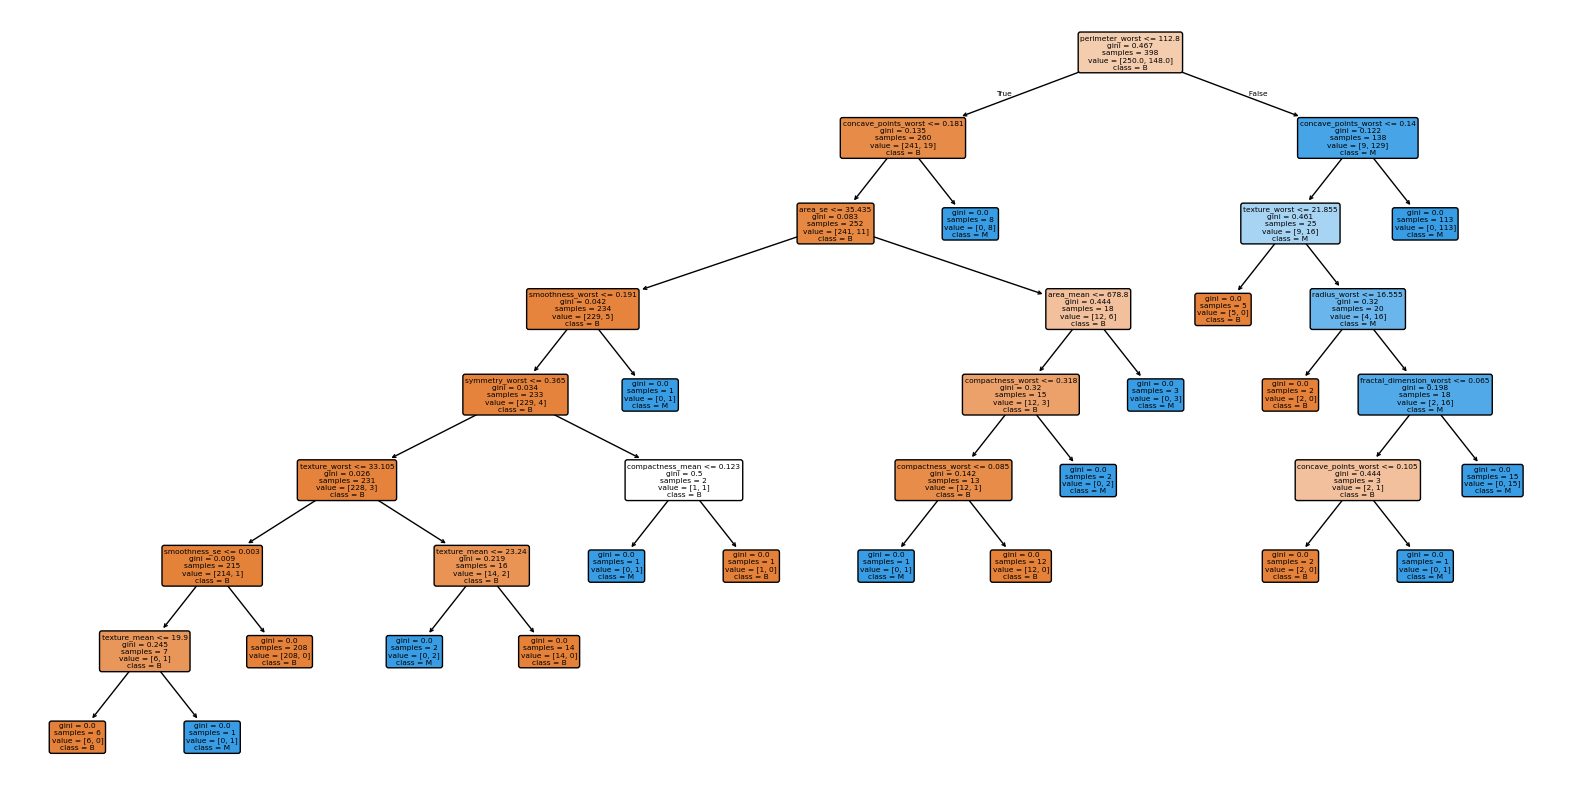

In [7]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Graficar el árbol
plt.figure(figsize=(20,10))  # Ajusta el tamaño según la complejidad
plot_tree(arbol, 
          feature_names=X_train.columns,  # Nombres de las variables
          class_names=[str(c) for c in arbol.classes_],  # Nombres de las clases
          filled=True,  # Colores según clase
          rounded=True) # Bordes redondeados
plt.show()

* Observemos que el árbol generado es bastante grande y hay muchas hojas que tienen 1 solo dato esto nos esta indicando que hay sobreajuste. (Overffiting) 
* ¿Cuál es la  profundidad del árbol?
* Para evitar el sobreajuste se recomienda reducir la complejidad del árbol

Parámetros configurados para el modelo:


| Parámetros                   | Ejemplo                        |    |
| --                           | --                             | -- |
| **criterion**                | criterion = 'gini'             | El criterio para medir la calidad de la división es el **índice de Gini**, que mide la impureza de los nodos. Alternativa: `'entropy'` (usa información) |
| **splitter**                 | splitter = 'best'              | El algoritmo elige la mejor división posible en cada nodo. Alternativa: `'random'` (elige divisiones aleatorias) |
| **max_depth**                | max_depth = None               | No hay límite en la profundidad del árbol. El árbol crecerá hasta que todas las hojas sean puras o hasta que no se pueda dividir más |
| **min_samples_split**        | min_samples_split = 2          | Número mínimo de muestras para dividir un nodo: **2**. Si un nodo tiene menos de 2 muestras, no se divide |
| **min_samples_leaf**         | min_samples_leaf = 1           | Número mínimo de muestras en una hoja: **1**. Permite hojas con una sola muestra |
| **min_weight_fraction_leaf** | min_weight_fraction_leaf = 0.0 | No se usa fracción mínima de peso para las hojas (solo relevante si hay pesos en las muestras) |
| **max_features**             | max_features = None            | Se usan todas las características para buscar la mejor división en cada nodo |
| **random_state**             | random_state = 123             | Fija la semilla aleatoria para reproducibilidad. Esto asegura que el árbol generado sea el mismo cada vez |
| **max_leaf_nodes**           | max_leaf_nodes = None          | No hay límite en el número de hojas. El árbol puede tener tantas hojas como permita la estructura |
| **min_impurity_decrease**    | min_impurity_decrease = 0.0    | No se requiere una disminución mínima de impureza para dividir un nodo                   |
| **class_weight**             | class_weight = None            | No se aplican pesos a las clases. Todas las clases tienen igual importancia              |
| **ccp_alpha**                | ccp_alpha = 0.0                | Parámetro para poda de complejidad mínima. Como es 0, no se realiza poda                 |
| **monotonic_cst**            | monotonic_cst = None           | No se aplican restricciones de monotonía (solo relevante en algunos contextos avanzados) |

* Interpretación general. Este árbol:
    - Crecerá sin límite de profundidad
    - Usará todas las variables para dividir
    - No tiene poda ni restricciones adicionales
    - Es reproducible porque `random_state = 123`

In [8]:
# Profundidad del árbol
profundidad = arbol.get_depth()
profundidad

8

In [9]:
# Número de hojas
num_hojas = arbol.get_n_leaves()
num_hojas

19

## Efecto de los hiper-parámetros en el desempeño del árbol

* Comencemos viendo el desempeño del árbol que creamos inicialmente, haciendo uso de la validación cruzada (*k-fold cross-validation*)
* Como métrica de desempeño usaremos el F1-ponderado. Comencemos recordando qué son los falsos/verdaderos positivos y los falsos/verdaderos negativos:
* En la segunda columna del archivo (Diagnosis), se encuentran las etiquetas de diagnóstico:
    * M: Maligno (presencia de cáncer)
    * B: Benigno (ausencia de cáncer)

* ¿Qué significan TP y TN? El objetivo es detectar tumores MALIGNOS
* En el contexto de clasificación binaria (por ejemplo, si estás entrenando un modelo para predecir si un tumor es maligno o benigno), los términos se definen así:

|                                                |                                                                                             |
| --                                             | --                                                                                          |
| **TP** (True Positives / Verdaderos Positivos) | Casos en los que el modelo predice maligno (M) y el diagnóstico real también es maligno (M) |
| **TN** (True Negatives / Verdaderos Negativos) | Casos en los que el modelo predice benigno (B) y el diagnóstico real también es benigno (B) |
| **FP** (False Positives / Falsos Positivos)    | El modelo predice maligno (M) pero el diagnóstico real es benigno (B)                       |
| **FN** (False Negatives / Falsos Negativos)    | El modelo predice benigno (B) pero el diagnóstico real es maligno (M)                       |

La precision: ¿de todos los clasificados como **MALIGNOS** qué porcentaje son realmente **MALIGNOS**?:

$$precision = \dfrac{TP}{TP+FP}$$

El recall: ¿de todos los **MALIGNOS** qué proporción fue clasificada realmente como **MALIGNOS**

$$recall = \dfrac{TP}{TP+FN}$$

Y el F1-score combina el precision y el recall en una sola métrica:

$$F1 = \dfrac{2 * Precisión * Recall}{Precisión + Recall} = \dfrac {2TP}{2TP+FP+FN}$$

Y el F1-score ponderado simplemente modifica ligeramente las ecuaciones anteriores para compensar el desbalance de los datos

### F1-score ponderado (Weighted F1-score)

**¿Qué mide?**  
La media ponderada de los F1-scores de cada clase, teniendo en cuenta la cantidad de ejemplos por clase.

**Fórmula:**  

$$F1_i ponderado = F1_i * \Sigma \dfrac{N_i}{N}$$

Donde:  
- $N_i$ es el número de muestras de la clase i  
- $N$ es el número total de muestras  
- $F1_i$ es el F1-score de la clase i

**Interpretación:**  
Es útil cuando las clases están desbalanceadas, ya que refleja el rendimiento global del modelo considerando la proporción de cada clase.


Así que veamos el desempeño (F1-score ponderado) del árbol construido originalmente:

In [10]:
# Validación cruzada: datos de entrenamiento los divide en subgrupos 
# Toma el G1 y con los otros 4 entrena el modelo
# ...
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Crear particiones estratificadas (k=5)
skf = StratifiedKFold(n_splits=5,
                      shuffle=True,
                      random_state=123)

# Realizar validación cruzada (k-fold cross-validation)
arbol = DecisionTreeClassifier(random_state=123)
scores = cross_val_score(arbol, X_train, y_train, cv=skf, scoring='f1_weighted')

# Imprimir resultados validación cruzada
print("F1-score ponderado entrenamiento:", scores.mean())

# Entrenar el árbol con el set de entrenamiento
arbol.fit(X_train,y_train)

# Puntaje set de prueba
score_test = arbol.score(X_test, y_test)
print("F1-score ponderado prueba:", score_test)

F1-score ponderado entrenamiento: 0.9069442489392185
F1-score ponderado prueba: 0.8947368421052632


Y veamos si este desempeño cambia al modificar los hiper-parámetros del árbol. Los principales hiper-parámetros son:

- "max_depth": máxima profundidad del árbol (*None* por defecto)
- "min_samples_split": mínimo número de datos para generar partición (2 por defecto)
- "min_samples_leaf": mínimo número de datos que puede contener una hoja (1 por defecto)

Al modificar "max_depth", "min_samples_split" o "min_samples_leaf" haremos que el árbol sea más o menos complejo y esto afectará el desempeño.

Construyamos por ejemplo un árbol con una profundidad máxima de 5:

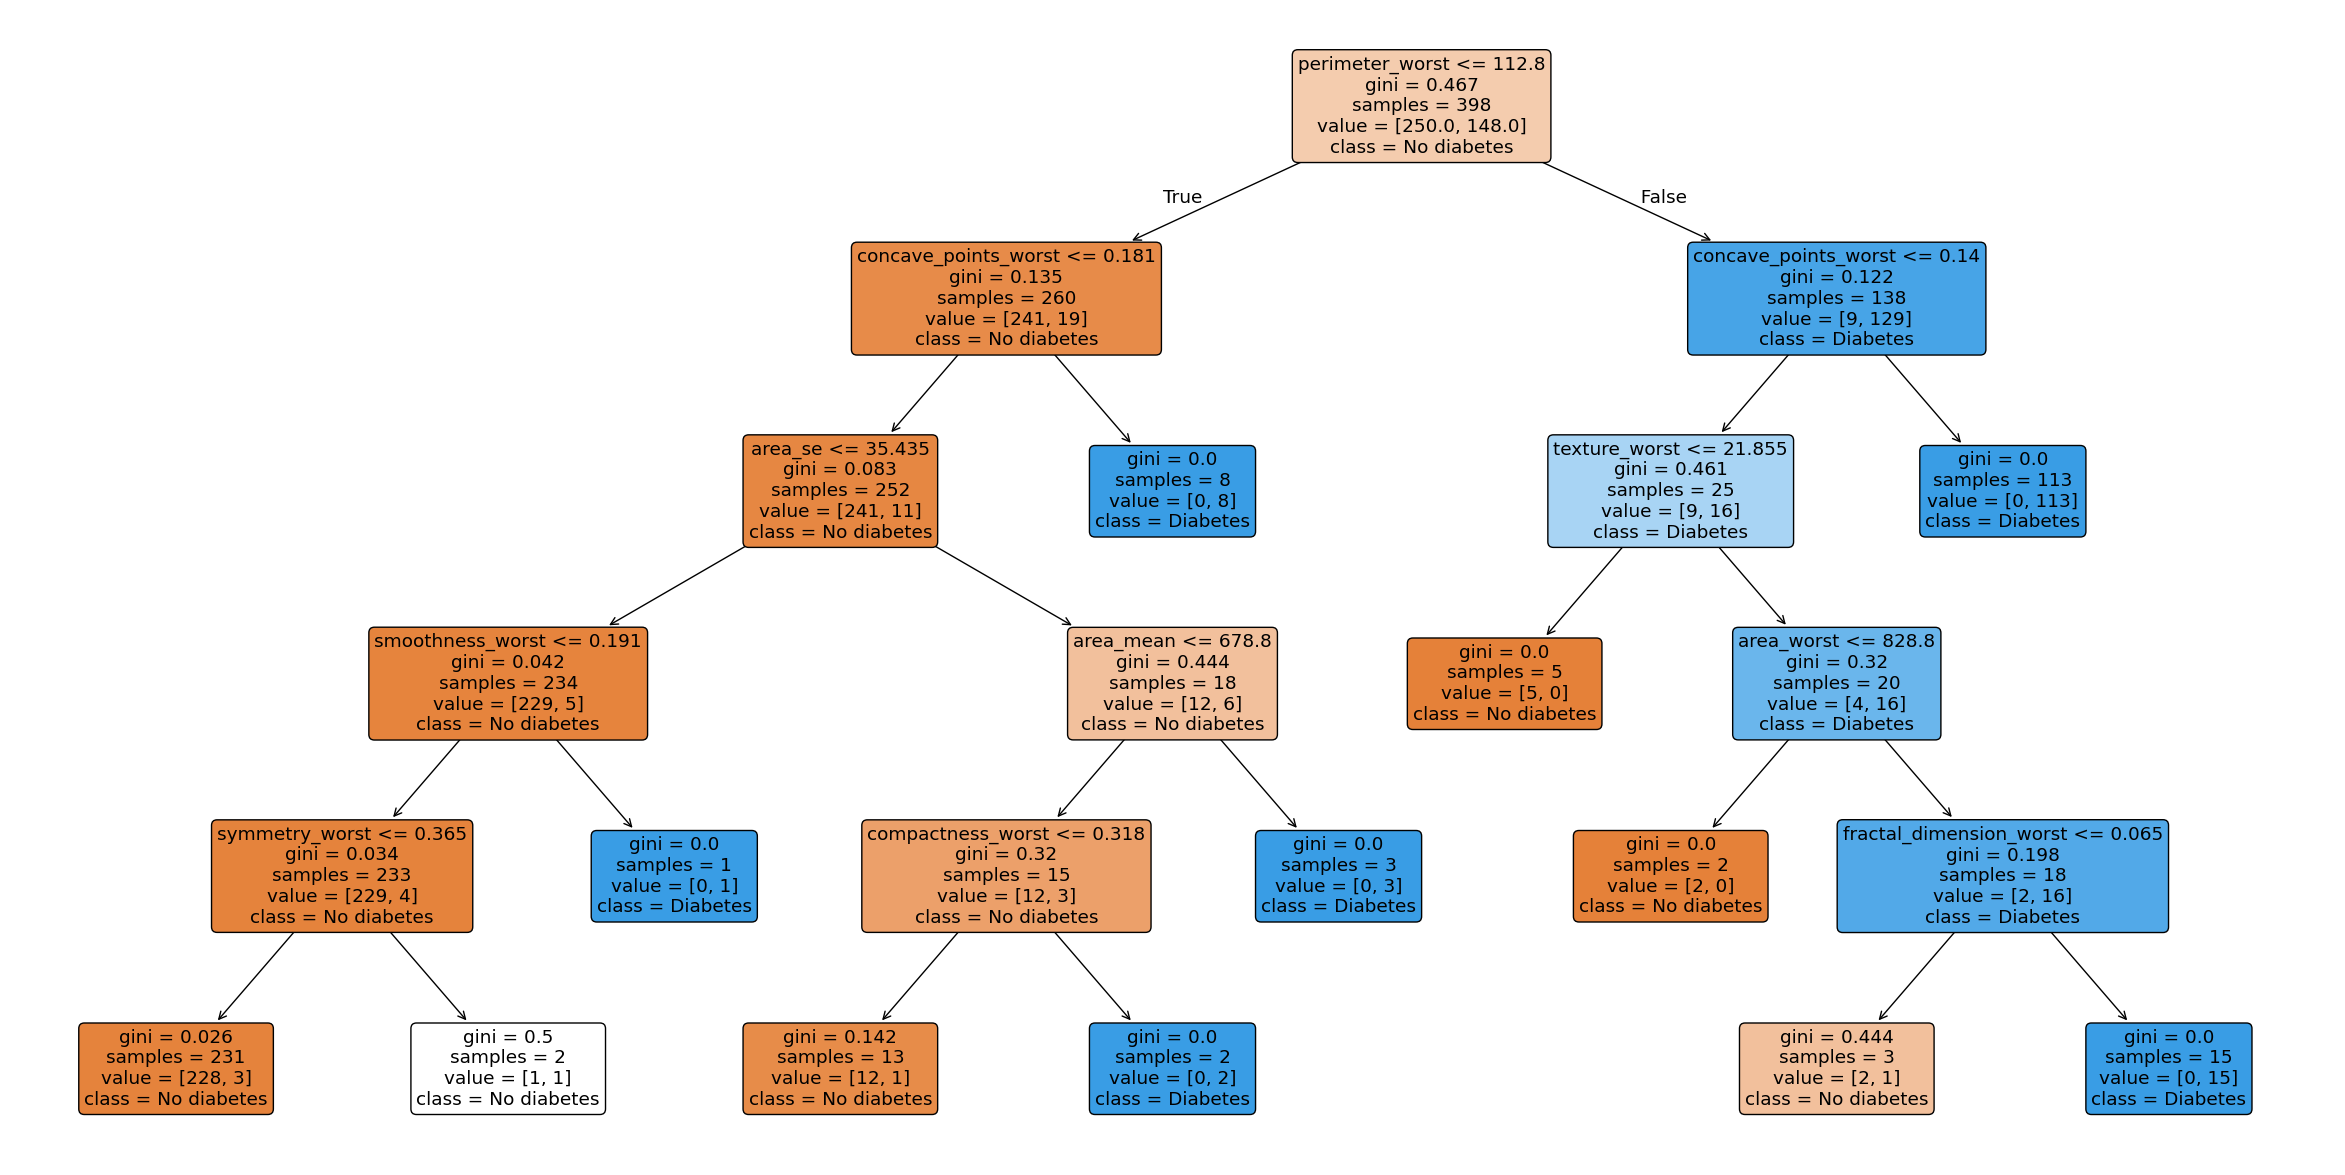

In [11]:
# Árbol con "max_depth" = 5

arbol = DecisionTreeClassifier(max_depth=5,
                               random_state=123)
arbol.fit(X_train, y_train)

plt.figure(figsize=(30, 15))  # Tamaño de la figura
plot_tree(arbol,
          feature_names=X_train.columns, # Para que contenga los nombres de las características
          class_names = ['No diabetes', 'Diabetes'], # Para que contenga los nombres de las categorías (en orden numérico ascendente)
          filled=True,  # Colorear las hojas con la categoría mayoritaria
          rounded=True, # Bordes redondeados
          );
# Guardar el árbol como archivo PNG de alta resolución
plt.savefig('arbol_clasificacion_maxdepth_5.png', dpi=700)

In [12]:
# Características del árbol
print('Profundidad del árbol: ', arbol.get_depth())
print('Número de hojas del árbol: ', arbol.get_n_leaves())

Profundidad del árbol:  5
Número de hojas del árbol:  12


La profundidad paso de 8 a 5 y el numero de hojas de 19 a 12

In [13]:
# Validación cruzada del árbol

# Crear particiones estratificadas (k=5)
skf = StratifiedKFold(n_splits=5,
                      shuffle=True,
                      random_state=123)

# Realizar validación cruzada (k-fold cross-validation)
arbol = DecisionTreeClassifier(max_depth=5,
                               random_state=123)
scores = cross_val_score(arbol, X_train, y_train, cv=skf, scoring='f1_weighted')

# Imprimir resultados validación cruzada
print("F1-score ponderado entrenamiento:", scores.mean())
arbol.fit(X_train,y_train)

# Puntaje set de prueba
score_test = arbol.score(X_test, y_test)
print("F1-score ponderado prueba:", score_test)

F1-score ponderado entrenamiento: 0.9139075607974693
F1-score ponderado prueba: 0.9064327485380117


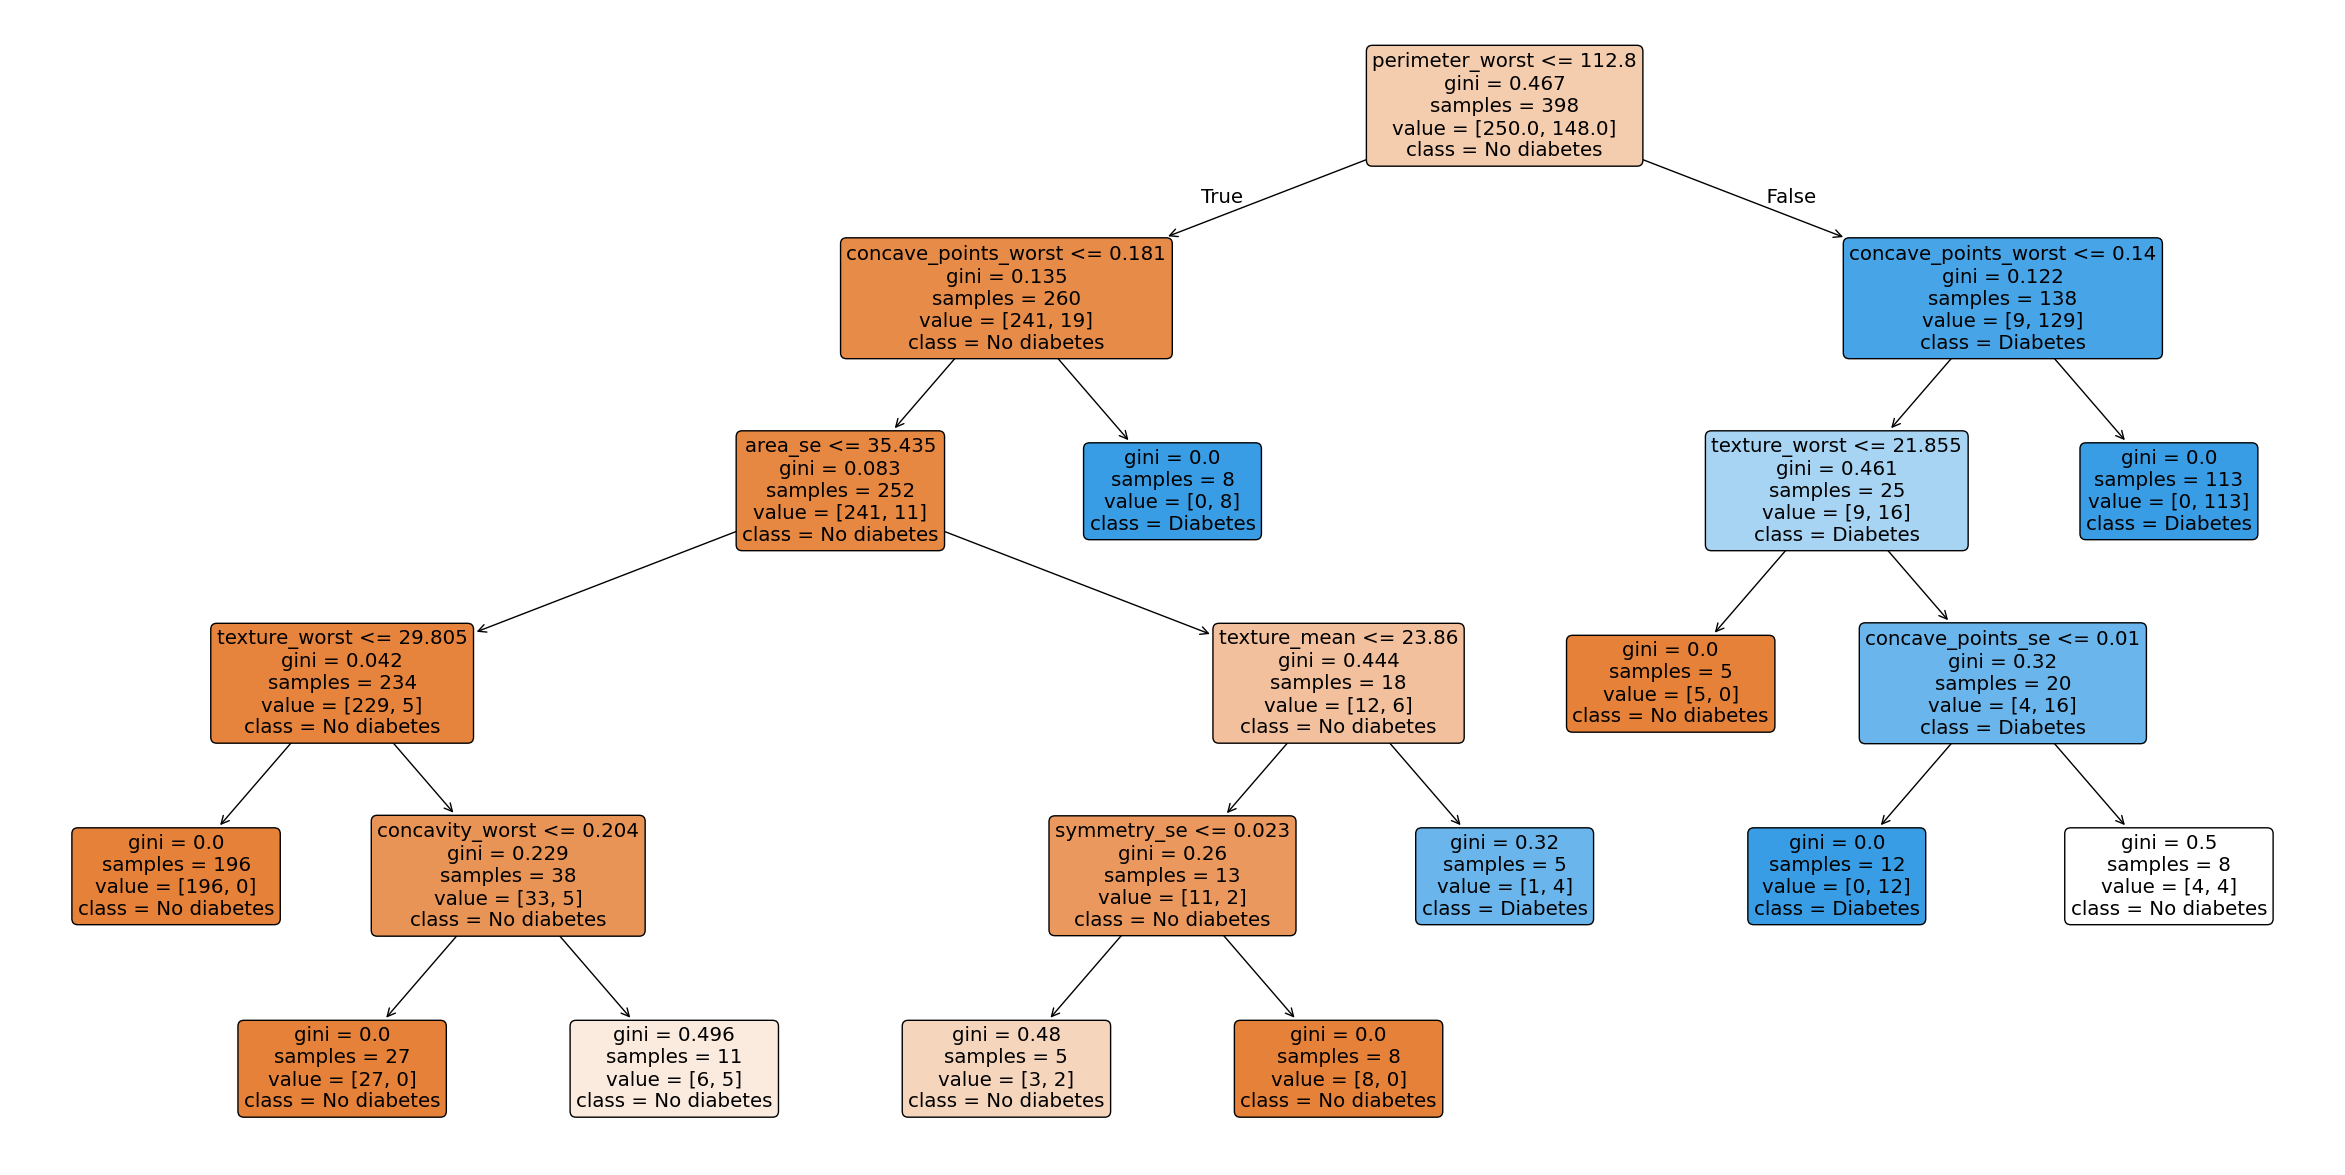

In [14]:
# Árbol con:
# - max_depth = 5
# - min_samples_leaf = 5

arbol = DecisionTreeClassifier(max_depth=5,
                               min_samples_leaf=5,
                               random_state=123)
arbol.fit(X_train, y_train)

plt.figure(figsize=(30, 15))  # Tamaño de la figura
plot_tree(arbol,
          feature_names=X_train.columns, # Para que contenga los nombres de las características
          class_names = ['No diabetes', 'Diabetes'], # Para que contenga los nombres de las categorías (en orden numérico ascendente)
          filled=True,  # Colorear las hojas con la categoría mayoritaria
          rounded=True, # Bordes redondeados
          );

# Guardar el árbol como archivo PNG de alta resolución
plt.savefig('arbol_clasificacion_maxdepth_5_minsamplesleaf_4.png', dpi=700)

In [15]:
# Características del árbol
print('Profundidad del árbol: ', arbol.get_depth())
print('Número de hojas del árbol: ', arbol.get_n_leaves())

Profundidad del árbol:  5
Número de hojas del árbol:  11


In [16]:
# Validación cruzada del árbol

# Crear particiones estratificadas (k=5)
skf = StratifiedKFold(n_splits=5,
                      shuffle=True,
                      random_state=123)

# Realizar validación cruzada (k-fold cross-validation)
scores = cross_val_score(arbol, X_train, y_train, cv=skf, scoring='f1_weighted')
arbol = DecisionTreeClassifier(max_depth=5,
                               min_samples_leaf=4,
                               random_state=123)


# Imprimir resultados validación cruzada
print("F1-score ponderado entrenamiento:", scores.mean())
arbol.fit(X_train,y_train)


arbol.fit(X_train, y_train)

# Puntaje set de prueba
score_test = arbol.score(X_test, y_test)
print("Exactitud prueba:", score_test)


F1-score ponderado entrenamiento: 0.9269494517687082
Exactitud prueba: 0.9298245614035088


Predicciones

In [17]:
# Y finalmente predicciones
preds = arbol.predict(X_test)
preds

array(['B', 'B', 'B', 'B', 'B', 'B', 'M', 'B', 'M', 'B', 'B', 'M', 'B',
       'B', 'B', 'B', 'B', 'M', 'M', 'M', 'M', 'B', 'M', 'B', 'B', 'M',
       'M', 'M', 'B', 'B', 'B', 'B', 'B', 'M', 'B', 'B', 'M', 'M', 'B',
       'M', 'M', 'B', 'M', 'B', 'B', 'M', 'B', 'B', 'B', 'B', 'B', 'B',
       'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'M', 'M',
       'M', 'M', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'M', 'B', 'B', 'M',
       'B', 'B', 'B', 'B', 'B', 'M', 'B', 'M', 'B', 'B', 'B', 'B', 'B',
       'M', 'M', 'M', 'M', 'M', 'B', 'B', 'B', 'B', 'B', 'M', 'M', 'B',
       'M', 'B', 'M', 'M', 'B', 'M', 'B', 'B', 'B', 'B', 'M', 'B', 'B',
       'M', 'B', 'B', 'M', 'B', 'B', 'M', 'B', 'B', 'B', 'B', 'M', 'M',
       'M', 'B', 'B', 'M', 'B', 'M', 'B', 'B', 'B', 'B', 'B', 'M', 'B',
       'B', 'B', 'B', 'B', 'B', 'B', 'M', 'M', 'B', 'B', 'B', 'B', 'B',
       'B', 'B', 'M', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'M', 'B',
       'B', 'M'], dtype=object)